# Disney Apriori Analysis (train/test CSVs only)

Apriori-focused notebook built **only** from `disney_movies_train.csv` and `disney_movies_test.csv`. Linear regression is handled by a groupmate.

The code comments tag each change: `[KEPT]` same idea as before, `[CHANGED]` reorganized or fixed, `[ADDED]` new step, `[REMOVED]` dropped.

**What is in this version**

1. **Descriptive statistics** written like the GeloBot midterm (one small cell per column, labeled prints, one plot per cell) and using the `kapitel_04` functions (`statistics`, `stats.iqr`, `histplot` + `kdeplot` + `rugplot`, `boxplot`, `regplot`, `heatmap`).
2. **Every graph has a legend or labels** that say what each part is (mean and median lines, outliers, whiskers, kept vs dropped, and so on), so it can be read on a slide.
3. **ONE itemset table** (with a `k` column) and **ONE rules table** (which also holds the train/test check).
4. **8 films excluded from Apriori** because their genre list belongs to a different version of the film.
5. **Result graphs are three separate figures**, one per slide.

In [ ]:
import ast
from itertools import combinations
import statistics                 # kapitel_04: mean, median, mode, stdev
import numpy as np
import pandas as pd
# import scipy.stats as stats       # kapitel_04: stats.iqr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches   # legend boxes
import matplotlib.lines as mlines       # legend lines
import seaborn as sns             # kapitel_04: histplot, kdeplot, rugplot, boxplot, regplot, heatmap

pd.set_option("display.width", 200)

ModuleNotFoundError: No module named 'scipy'

## 1. Data and structure (descriptive statistics)

In [ ]:
# =====================  LOAD THE GIVEN TRAIN / TEST FILES  =====================
# [CHANGED] Only the two given CSVs are loaded. The title-matching merge with titles.csv is gone.

train_raw = pd.read_csv("disney_train_clean.csv"); train_raw["split"] = "train"
test_raw = pd.read_csv("disney_test_clean.csv");   test_raw["split"] = "test"
full = pd.concat([train_raw, test_raw], ignore_index=True)

# [KEPT] Dates and a year column (used for era and for the descriptive plots).
full["release_date"] = pd.to_datetime(full["release_date"])
full["year"] = full["release_date"].dt.year
full["decade"] = (full["year"] // 10) * 10

# [KEPT] The genre column mixes two formats: a real list "['animation', 'family']" or a single label / NaN.
full["has_list"] = full["genre"].fillna("").str.startswith("[")

# [ADDED] Lecture "Goal of Data Exploration": structure, size, completeness.
cols = ["movie_title", "release_date", "genre", "mpaa_rating", "total_gross", "inflation_adjusted_gross"]
structure = pd.DataFrame({"dtype": full[cols].dtypes.astype(str),
                          "missing": full[cols].isna().sum(),
                          "unique values": full[cols].nunique()})
print(f"Films: {len(full)}  (train {len(train_raw)} + test {len(test_raw)})   Columns: {len(cols)}\n")
print(structure.to_string())
print(f"\nFilms with a genre LIST (usable as Apriori baskets): {int(full['has_list'].sum())} of {len(full)}")

Films: 579  (train 463 + test 116)   Columns: 6

                                   dtype  missing  unique values
movie_title                          str        0            573
release_date              datetime64[us]        0            553
genre                                str       13            180
mpaa_rating                          str       56              5
total_gross                        int64        0            576
inflation_adjusted_gross           int64        0            576

Films with a genre LIST (usable as Apriori baskets): 222 of 579


### Dataset information and summary table

In [ ]:
# Dataset Information

print(full[cols].info())
print()
print(full[["total_gross", "inflation_adjusted_gross", "year"]].describe())

<class 'pandas.DataFrame'>
RangeIndex: 579 entries, 0 to 578
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   movie_title               579 non-null    str           
 1   release_date              579 non-null    datetime64[us]
 2   genre                     566 non-null    str           
 3   mpaa_rating               523 non-null    str           
 4   total_gross               579 non-null    int64         
 5   inflation_adjusted_gross  579 non-null    int64         
dtypes: datetime64[us](1), int64(2), str(3)
memory usage: 27.3 KB
None

        total_gross  inflation_adjusted_gross         year
count  5.790000e+02              5.790000e+02   579.000000
mean   6.470179e+07              1.187625e+08  1998.012090
std    9.301301e+07              2.860853e+08    11.410924
min    0.000000e+00              0.000000e+00  1937.000000
25%    1.278886e+07              2.274123e+0

In [ ]:
# Summary table: Mean, Median, Std, IQR, Min, Max (kapitel_04 measures) for the numeric columns

num = ["total_gross", "inflation_adjusted_gross", "year"]
summary = pd.DataFrame({
    "Mean": [full[c].mean() for c in num],
    "Median": [full[c].median() for c in num],
    "Std": [full[c].std() for c in num],
    "IQR": [stats.iqr(full[c]) for c in num],
    "Min": [full[c].min() for c in num],
    "Max": [full[c].max() for c in num]}, index=num)

print(summary.to_string(float_format=lambda v: f"{v:,.2f}"))

                                   Mean        Median            Std           IQR   Min         Max
total_gross               64,701,788.52 30,702,446.00  93,013,006.12 62,920,169.00     0   936662225
inflation_adjusted_gross 118,762,523.31 55,159,783.00 286,085,280.04 96,460,768.00     0  5228953251
year                           1,998.01      1,998.00          11.41         13.00  1937        2016


### Descriptive statistics per column

In [ ]:
# Mean, Median, Std, IQR, Range for Total Gross Column
# (Mode is skipped on purpose: gross is continuous, and kapitel_04 says not to use the mode for continuous data)

gross_column = full['total_gross']

print("Mean(Total Gross): ", gross_column.mean())
print("Median(Total Gross): ", gross_column.median())
print("Standard Deviation(Total Gross): ", gross_column.std())
print("IQR(Total Gross): ", stats.iqr(gross_column))
print("Min(Total Gross): ", gross_column.min())
print("Max(Total Gross): ", gross_column.max())

range_gross = gross_column.max() - gross_column.min()
print("Range(Total Gross): ", range_gross)

Mean(Total Gross):  64701788.51986183
Median(Total Gross):  30702446.0
Standard Deviation(Total Gross):  93013006.11742666
IQR(Total Gross):  62920169.0
Min(Total Gross):  0
Max(Total Gross):  936662225
Range(Total Gross):  936662225


In [ ]:
# Mean, Median, Std, IQR, Range for Inflation Adjusted Gross Column

adj_gross_column = full['inflation_adjusted_gross']

print("Mean(Inflation Adjusted Gross): ", adj_gross_column.mean())
print("Median(Inflation Adjusted Gross): ", adj_gross_column.median())
print("Standard Deviation(Inflation Adjusted Gross): ", adj_gross_column.std())
print("IQR(Inflation Adjusted Gross): ", stats.iqr(adj_gross_column))
print("Min(Inflation Adjusted Gross): ", adj_gross_column.min())
print("Max(Inflation Adjusted Gross): ", adj_gross_column.max())

range_adj = adj_gross_column.max() - adj_gross_column.min()
print("Range(Inflation Adjusted Gross): ", range_adj)

# Mean is far above the median and the sd is much bigger than the IQR: a few blockbusters pull the mean up (kapitel_04 outlier example)
print("Films with zero gross: ", int((adj_gross_column == 0).sum()))

Mean(Inflation Adjusted Gross):  118762523.31088082
Median(Inflation Adjusted Gross):  55159783.0
Standard Deviation(Inflation Adjusted Gross):  286085280.04141724
IQR(Inflation Adjusted Gross):  96460768.0
Min(Inflation Adjusted Gross):  0
Max(Inflation Adjusted Gross):  5228953251
Range(Inflation Adjusted Gross):  5228953251
Films with zero gross:  4


In [ ]:
# Mean, Median, Mode, Std, IQR, Range for Release Year Column

year_column = full['year']

print("Mean(Year): ", year_column.mean())
print("Median(Year): ", year_column.median())
print("Mode(Year): ", statistics.mode(year_column.tolist()))
print("Standard Deviation(Year): ", year_column.std())
print("IQR(Year): ", stats.iqr(year_column))
print("Min(Year): ", year_column.min())
print("Max(Year): ", year_column.max())

range_year = year_column.max() - year_column.min()
print("Range(Year): ", range_year)

Mean(Year):  1998.0120898100172
Median(Year):  1998.0
Mode(Year):  1995
Standard Deviation(Year):  11.41092442110495
IQR(Year):  13.0
Min(Year):  1937
Max(Year):  2016
Range(Year):  79


In [ ]:
## MPAA rating types

rating_counts = full['mpaa_rating'].value_counts()
print(rating_counts)
print("Mode(MPAA Rating): ", statistics.mode(full['mpaa_rating'].dropna().tolist()))
print("Missing(MPAA Rating): ", full['mpaa_rating'].isna().sum())

mpaa_rating
PG           187
PG-13        145
R            102
G             86
Not Rated      3
Name: count, dtype: int64
Mode(MPAA Rating):  PG
Missing(MPAA Rating):  56


In [ ]:
## Genre label types (a genre list can be an Apriori basket, a single label cannot)

genre_types = full['has_list'].map({True: 'Genre list', False: 'Single label or missing'}).value_counts()
print(genre_types)
print("Missing(Genre): ", full['genre'].isna().sum())

has_list
Single label or missing    357
Genre list                 222
Name: count, dtype: int64
Missing(Genre):  13


In [ ]:
## Train vs test (is the given split representative?)

split_counts = full['split'].value_counts()
print(split_counts)

compare = full.groupby("split").agg(films=("movie_title", "size"), with_genre_list=("has_list", "sum"),
                                    median_year=("year", "median"), median_gross=("inflation_adjusted_gross", "median"))
compare["share_with_list"] = (compare["with_genre_list"] / compare["films"]).round(3)
print()
print(compare.to_string(float_format=lambda v: f"{v:,.3f}"))

split
train    463
test     116
Name: count, dtype: int64

       films  with_genre_list  median_year   median_gross  share_with_list
split                                                                     
test     116               50    1,997.000 60,520,563.500            0.431
train    463              172    1,998.000 53,693,680.000            0.371


### Plots of each column (every plot has a legend or labels for its parts)

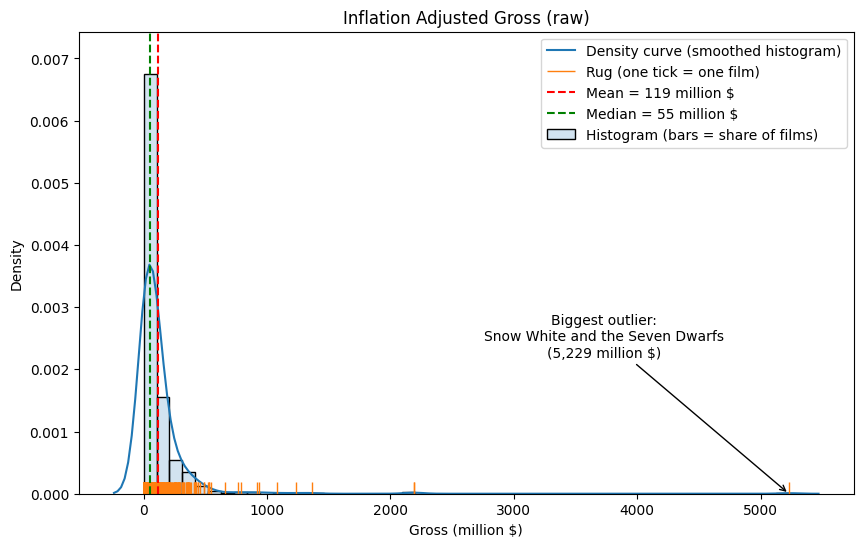

In [ ]:
## Inflation Adjusted Gross (raw)
# kapitel_04: histogram + density plot + rug in one plot. [ADDED] a legend for every layer, mean/median lines and the biggest outlier labeled.

gross_m = adj_gross_column / 1e6
top_film = full.loc[adj_gross_column.idxmax()]

plt.figure(figsize=(10, 6))
sns.histplot(gross_m, stat='density', alpha=0.2, bins=50, label='Histogram (bars = share of films)')
sns.kdeplot(gross_m, label='Density curve (smoothed histogram)')
sns.rugplot(gross_m, label='Rug (one tick = one film)')
plt.axvline(gross_m.mean(), color='red', linestyle='--', label=f'Mean = {gross_m.mean():,.0f} million $')
plt.axvline(gross_m.median(), color='green', linestyle='--', label=f'Median = {gross_m.median():,.0f} million $')
plt.annotate(f"Biggest outlier:\n{top_film['movie_title']}\n({top_film['inflation_adjusted_gross'] / 1e6:,.0f} million $)",
             xy=(gross_m.max(), 0), xytext=(gross_m.max() - 1500, 0.0022), ha='center',
             arrowprops=dict(arrowstyle='->'))
plt.title('Inflation Adjusted Gross (raw)')
plt.xlabel('Gross (million $)')
plt.ylabel('Density')
plt.legend()
plt.grid(False)
plt.show()

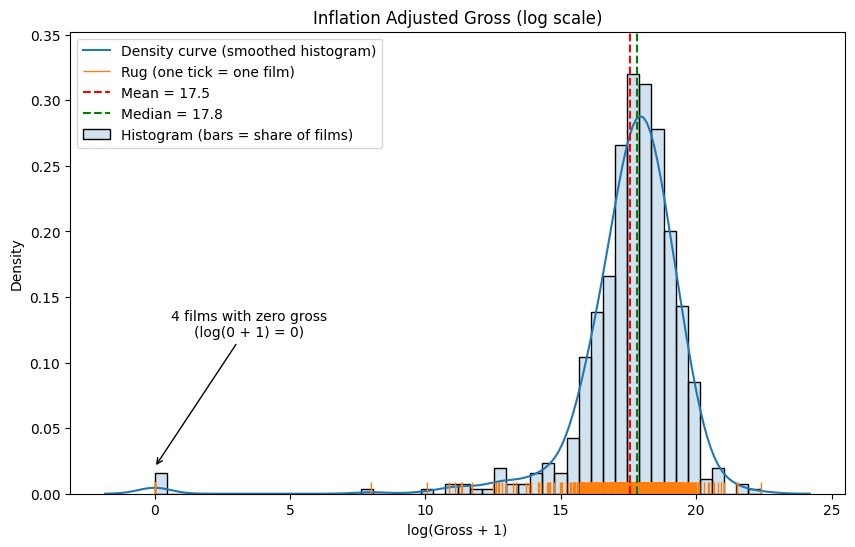

In [ ]:
## Inflation Adjusted Gross (log)
# kapitel_04: log(x+1) makes the skewed data readable. [ADDED] legend, mean/median lines and the zero-gross bump explained.

full['log_gross'] = np.log1p(adj_gross_column)
n_zero = int((adj_gross_column == 0).sum())

plt.figure(figsize=(10, 6))
sns.histplot(full['log_gross'], stat='density', alpha=0.2, bins=50, label='Histogram (bars = share of films)')
sns.kdeplot(full['log_gross'], label='Density curve (smoothed histogram)')
sns.rugplot(full['log_gross'], label='Rug (one tick = one film)')
plt.axvline(full['log_gross'].mean(), color='red', linestyle='--', label=f"Mean = {full['log_gross'].mean():.1f}")
plt.axvline(full['log_gross'].median(), color='green', linestyle='--', label=f"Median = {full['log_gross'].median():.1f}")
plt.annotate(f"{n_zero} films with zero gross\n(log(0 + 1) = 0)", xy=(0, 0.02), xytext=(3.5, 0.12), ha='center',
             arrowprops=dict(arrowstyle='->'))
plt.title('Inflation Adjusted Gross (log scale)')
plt.xlabel('log(Gross + 1)')
plt.ylabel('Density')
plt.legend(loc='upper left')
plt.grid(False)
plt.show()

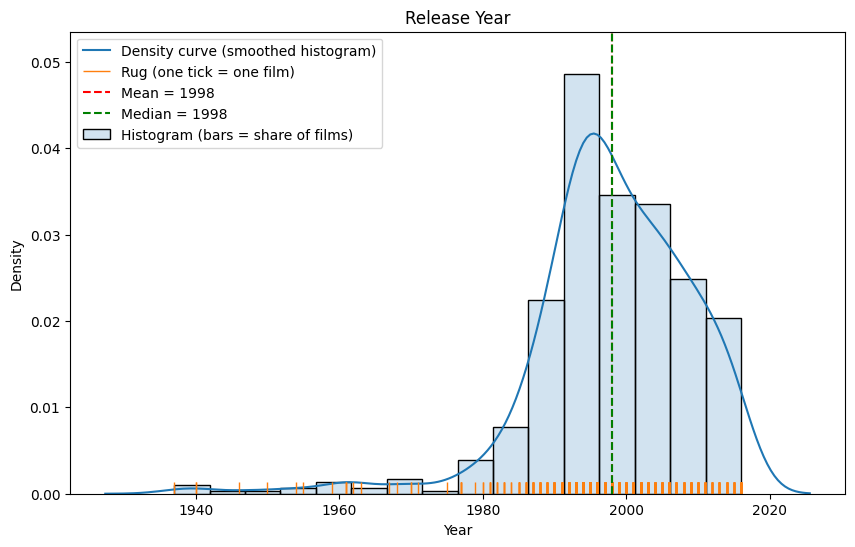

In [ ]:
## Release Year
# [ADDED] legend for the three layers and the mean/median lines

plt.figure(figsize=(10, 6))
sns.histplot(year_column, stat='density', alpha=0.2, bins=16, label='Histogram (bars = share of films)')
sns.kdeplot(year_column, label='Density curve (smoothed histogram)')
sns.rugplot(year_column, label='Rug (one tick = one film)')
plt.axvline(year_column.mean(), color='red', linestyle='--', label=f'Mean = {year_column.mean():.0f}')
plt.axvline(year_column.median(), color='green', linestyle='--', label=f'Median = {year_column.median():.0f}')
plt.title('Release Year')
plt.xlabel('Year')
plt.ylabel('Density')
plt.legend(loc='upper left')
plt.grid(False)
plt.show()

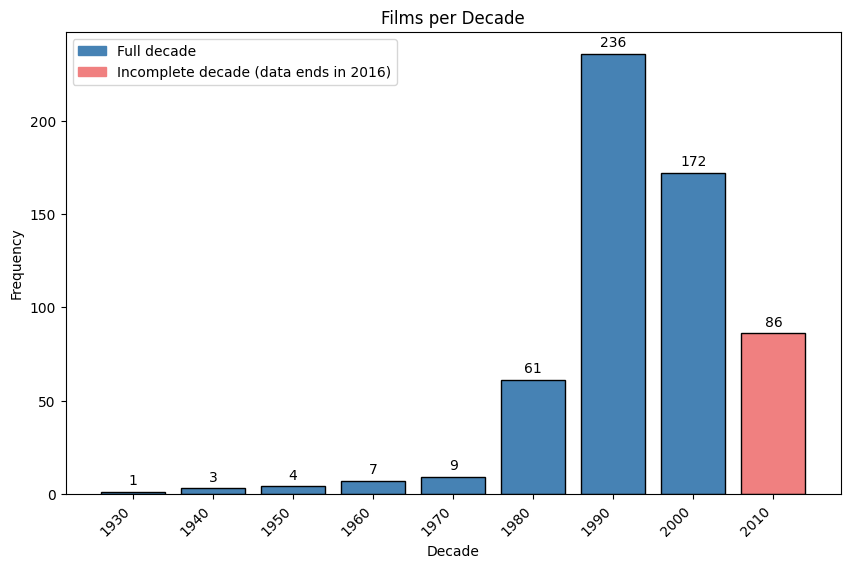

In [ ]:
## Films per Decade
# [ADDED] count on every bar, and the 2010s bar colored differently because the data stops in 2016

decade_counts = full['decade'].value_counts().sort_index()
bar_colors = ['steelblue'] * (len(decade_counts) - 1) + ['lightcoral']

plt.figure(figsize=(10, 6))
bars = plt.bar(decade_counts.index.astype(str), decade_counts.values, color=bar_colors, edgecolor='black')
plt.bar_label(bars, padding=3)
plt.legend(handles=[mpatches.Patch(color='steelblue', label='Full decade'),
                    mpatches.Patch(color='lightcoral', label='Incomplete decade (data ends in 2016)')])
plt.title('Films per Decade')
plt.xlabel('Decade')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha="right")
plt.grid(False)
plt.show()

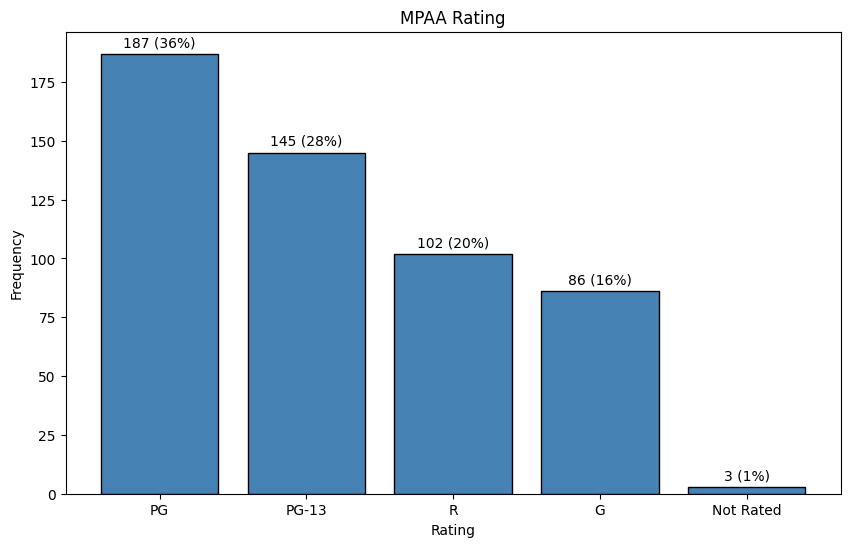

In [ ]:
## MPAA Rating
# [ADDED] count and share on every bar

plt.figure(figsize=(10, 6))
bars = plt.bar(rating_counts.index, rating_counts.values, color='steelblue', edgecolor='black')
plt.bar_label(bars, labels=[f"{v} ({v / rating_counts.sum():.0%})" for v in rating_counts.values], padding=3)
plt.title('MPAA Rating')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.grid(False)
plt.show()

### Relationships between columns

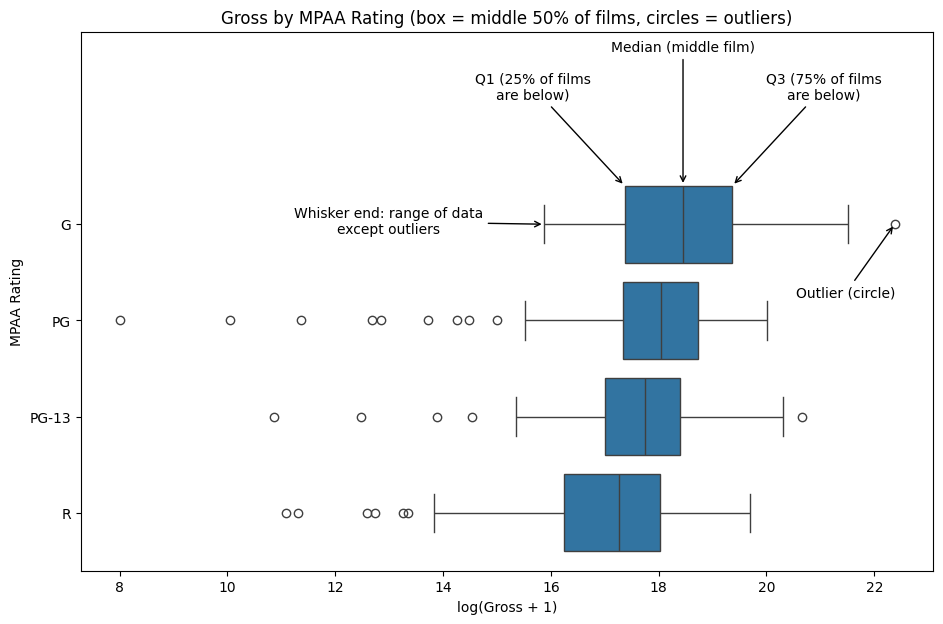

In [ ]:
## Gross by MPAA Rating
# kapitel_04: boxplot per group ('Not Rated' has only 3 films, so it is left out).
# [ADDED] The top box (G) is labeled part by part, like the boxplot slide in the lecture: Q1, median, Q3, whisker, outlier.

rated = full[full['mpaa_rating'].isin(['G', 'PG', 'PG-13', 'R'])]

g = rated.loc[rated['mpaa_rating'] == 'G', 'log_gross']
q1, med, q3 = g.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
whisker_low = g[g >= q1 - 1.5 * iqr].min()
outlier = g[(g < q1 - 1.5 * iqr) | (g > q3 + 1.5 * iqr)].max()

plt.figure(figsize=(11, 7))
sns.boxplot(x=rated['log_gross'], y=rated['mpaa_rating'], order=['G', 'PG', 'PG-13', 'R'], orient='h')
plt.ylim(3.6, -2.0)                                  # extra room above the top box for the labels
arrow = dict(arrowstyle='->')
plt.annotate('Q1 (25% of films\nare below)', xy=(q1, -0.4), xytext=(q1 - 1.7, -1.3), ha='center', arrowprops=arrow)
plt.annotate('Median (middle film)', xy=(med, -0.4), xytext=(med, -1.8), ha='center', arrowprops=arrow)
plt.annotate('Q3 (75% of films\nare below)', xy=(q3, -0.4), xytext=(q3 + 1.7, -1.3), ha='center', arrowprops=arrow)
plt.annotate('Whisker end: range of data\nexcept outliers', xy=(whisker_low, 0), xytext=(whisker_low - 2.9, 0.1), ha='center', arrowprops=arrow)
plt.annotate('Outlier (circle)', xy=(outlier, 0), xytext=(outlier - 0.9, 0.75), ha='center', arrowprops=arrow)
plt.title('Gross by MPAA Rating (box = middle 50% of films, circles = outliers)')
plt.xlabel('log(Gross + 1)')
plt.ylabel('MPAA Rating')
plt.grid(False)
plt.show()

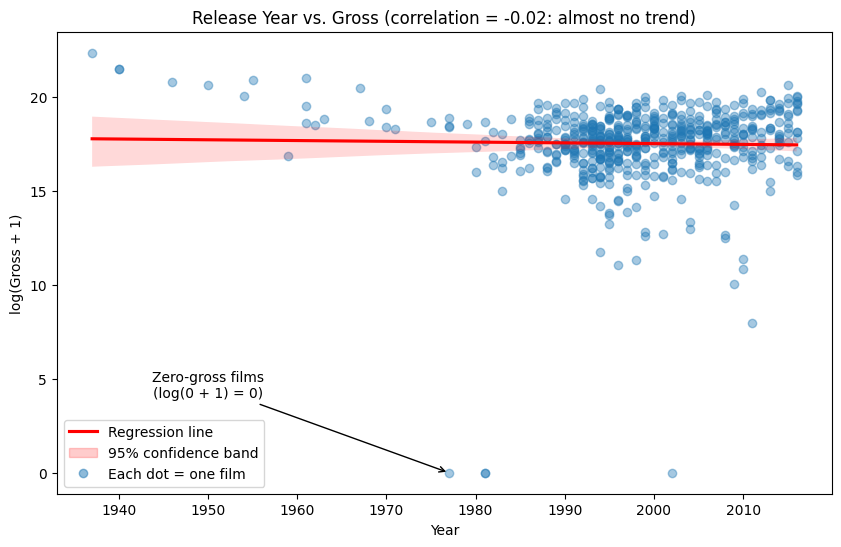

In [ ]:
## Release Year vs Gross
# kapitel_04: scatterplot with regression line. [ADDED] legend for dots, line and band, and the zero-gross films labeled.

plt.figure(figsize=(10, 6))
sns.regplot(x='year', y='log_gross', data=full,
            scatter_kws={'alpha': 0.4}, line_kws={'color': 'red', 'label': 'Regression line'})
zero_films = full[full['log_gross'] == 0].sort_values('year')
plt.annotate('Zero-gross films\n(log(0 + 1) = 0)', xy=(zero_films['year'].iloc[0], 0), xytext=(1950, 4), ha='center',
             arrowprops=dict(arrowstyle='->'))
handles, labels = plt.gca().get_legend_handles_labels()
handles.append(mpatches.Patch(color='red', alpha=0.2, label='95% confidence band'))
handles.append(mlines.Line2D([], [], marker='o', color='tab:blue', alpha=0.5, linestyle='', label='Each dot = one film'))
plt.legend(handles=handles, loc='lower left')
plt.title(f"Release Year vs. Gross (correlation = {full['year'].corr(full['log_gross']):.2f}: almost no trend)")
plt.xlabel('Year')
plt.ylabel('log(Gross + 1)')
plt.grid(False)
plt.show()

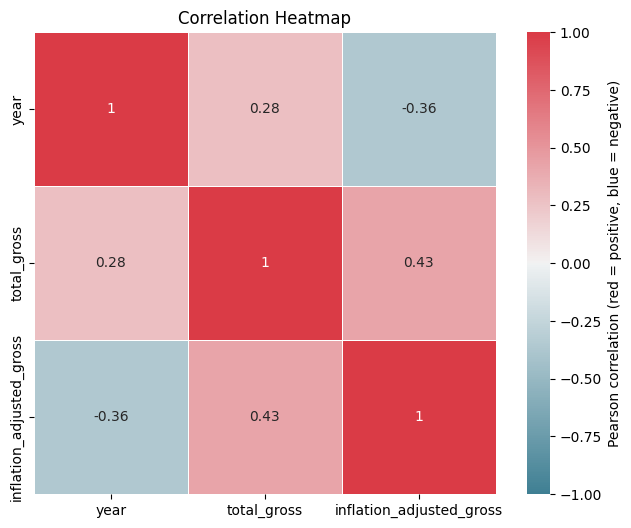

In [ ]:
## Correlation Heatmap
# kapitel_04: Pearson correlation (it measures linear relationships). [ADDED] colorbar label so the colors are explained.

corr = full[['year', 'total_gross', 'inflation_adjusted_gross']].corr()

plt.figure(figsize=(8, 6))
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(corr, square=True, linewidths=.5, vmin=-1.0, vmax=1.0, cmap=cmap, annot=True,
            cbar_kws={'label': 'Pearson correlation (red = positive, blue = negative)'})
plt.title('Correlation Heatmap')
plt.show()

## 2. Preparing the Apriori baskets

In [ ]:
# =====================  BASKETS FOR APRIORI  =====================
# [KEPT] Only films with a real genre list can be baskets (one-label films have a single item).
# [ADDED] These 8 films keep genre lists that belong to a different version of the film
#         (for example 1991 Beauty and the Beast carries the 2017 remake's genres, and both Jungle Books carry 2016's).
#         They are excluded from Apriori only. They stay in the descriptive statistics above because gross and year are valid.
WRONG_MATCH = {("Beauty and the Beast", 1991), ("The Jungle Book", 1967), ("The Jungle Book", 1994), ("Cinderella", 2015),
               ("Freaky Friday", 1977), ("101 Dalmatians", 1961), ("The Rescue", 1988), ("The Shaggy Dog", 2006)}

def parse_genres(g):
    return sorted(set(str(x).lower().strip() for x in ast.literal_eval(g)))

apr = full[full["has_list"]].copy()
n_list = len(apr)
apr = apr[[(t, y) not in WRONG_MATCH for t, y in zip(apr["movie_title"], apr["year"])]].reset_index(drop=True)
apr["genre_basket"] = apr["genre"].apply(parse_genres)

print(f"Films with a genre list : {n_list}")
print(f"Excluded (wrong version): {n_list - len(apr)}")
print(f"Apriori dataset         : {len(apr)}   -> {apr['split'].value_counts().to_dict()}")
apr.drop(columns=["has_list"]).to_csv("disney_apriori_clean.csv", index=False)

# [KEPT] Each basket is a set of genres.
transactions = [set(b) for b in apr["genre_basket"]]
train_tx = [set(b) for b in apr.loc[apr["split"] == "train", "genre_basket"]]
test_tx = [set(b) for b in apr.loc[apr["split"] == "test", "genre_basket"]]
N = len(transactions)
minsupp = 0.15
print(f"Average genres per film : {sum(len(t) for t in transactions) / N:.2f}   |   minsupp = {minsupp} (about {int(np.ceil(minsupp * N))} films)")

Films with a genre list : 222
Excluded (wrong version): 8
Apriori dataset         : 214   -> {'train': 167, 'test': 47}
Average genres per film : 3.70   |   minsupp = 0.15 (about 33 films)


## 3. Apriori: frequent itemsets

In [ ]:
# =====================  APRIORI FUNCTIONS  =====================
# [KEPT] support() = share of films that contain every item of the itemset (lecture slide).
def support(itemset, tx):
    s = set(itemset)
    return sum(1 for t in tx if s.issubset(t)) / len(tx)

# [CHANGED] Before: the function printed one separate table per k (k=1, k=2, k=3, k=4).
#           Now: it RETURNS (a) a dictionary of frequent itemsets and (b) ONE table with a "k" column.
#           The growing logic is unchanged: build candidates only from frequent (k-1)-subsets (Apriori property),
#           count support, keep or drop, and stop when no itemset survives.
def apriori_manual(tx, minsupp):
    frequent, rows = {}, []
    items = sorted({i for t in tx for i in t})
    Lk = []
    for i in items:                                                     # k = 1
        s = support({i}, tx); keep = s >= minsupp
        rows.append((1, frozenset([i]), s, keep))
        if keep:
            frequent[frozenset([i])] = s; Lk.append(frozenset([i]))
    k = 2
    while Lk:                                                           # k >= 2
        prev = set(Lk)
        pool = sorted(set().union(*Lk))
        cands = [frozenset(c) for c in combinations(pool, k)
                 if all(frozenset(sub) in prev for sub in combinations(c, k - 1))]
        if not cands:
            break
        Lk = []
        for c in cands:
            s = support(c, tx); keep = s >= minsupp
            rows.append((k, c, s, keep))
            if keep:
                frequent[c] = s; Lk.append(c)
        k += 1
    table = pd.DataFrame([{"k": kk, "Itemset": "{" + ", ".join(sorted(c)) + "}", "Support": round(s, 3),
                           "Status": "Keep" if keep else "Drop"} for kk, c, s, keep in rows])
    return frequent, table

In [ ]:
# =====================  RUN APRIORI  =====================
# [CHANGED] ONE combined itemset table (all k together) instead of four separate tables,
#           plus a small summary of how many itemsets were kept or dropped at each level.
frequent, itemset_table = apriori_manual(transactions, minsupp)
print(itemset_table.to_string(index=False))

summary = itemset_table.groupby("k")["Status"].value_counts().unstack(fill_value=0)
print("\nKept / dropped per level:")
print(summary.to_string())
print(f"\nLargest frequent itemset: size {max(len(s) for s in frequent)}  (growing stops because no larger itemset reaches minsupp)")

 k                              Itemset  Support Status
 1                             {action}    0.257   Keep
 1                          {animation}    0.360   Keep
 1                             {comedy}    0.659   Keep
 1                              {crime}    0.070   Drop
 1                      {documentation}    0.056   Drop
 1                              {drama}    0.369   Keep
 1                           {european}    0.070   Drop
 1                             {family}    0.799   Keep
 1                            {fantasy}    0.383   Keep
 1                            {history}    0.037   Drop
 1                             {horror}    0.023   Drop
 1                              {music}    0.061   Drop
 1                            {romance}    0.182   Keep
 1                              {scifi}    0.182   Keep
 1                              {sport}    0.103   Drop
 1                           {thriller}    0.047   Drop
 1                                {war}    0.014

In [ ]:
# =====================  WHY minsupp = 0.15?  =====================
# [CHANGED] One compact table (before: a loop printing five lines inside another cell).
sens = []
for ms in [0.05, 0.10, 0.15, 0.20, 0.30]:
    f, _ = apriori_manual(transactions, ms)
    sens.append({"minsupp": ms, "min films": int(np.ceil(ms * N)), "frequent itemsets": len(f),
                 "largest k": max((len(s) for s in f), default=0)})
print(pd.DataFrame(sens).to_string(index=False))

 minsupp  min films  frequent itemsets  largest k
    0.05         11                 83          5
    0.10         22                 35          4
    0.15         33                 23          4
    0.20         43                 17          3
    0.30         65                  8          2


## 4. Association rules and validation

In [ ]:
# =====================  RULES  =====================
# [KEPT] Rules for ALL frequent itemsets, with the lecture restrictions: no empty side, ONE item as consequent.
def generate_rules(frequent):
    rows = []
    for itemset, s_xy in frequent.items():
        if len(itemset) < 2:
            continue
        for r in range(1, len(itemset)):
            for ante in combinations(sorted(itemset), r):
                ante = frozenset(ante); cons = itemset - ante
                if len(cons) != 1:
                    continue
                s_x, s_y = frequent[ante], frequent[cons]               # subsets of frequent itemsets are frequent
                rows.append({"antecedent": ante, "consequent": cons,
                             "Rule": "{" + ", ".join(sorted(ante)) + "} => {" + ", ".join(sorted(cons)) + "}",
                             "Support": s_xy, "Confidence": s_xy / s_x,
                             "Lift": s_xy / (s_x * s_y), "Leverage": s_xy - s_x * s_y})
    return pd.DataFrame(rows).sort_values("Lift", ascending=False).reset_index(drop=True)

def eval_rule(ante, cons, tx):
    s_x, s_y, s_xy = support(ante, tx), support(cons, tx), support(ante | cons, tx)
    conf = s_xy / s_x if s_x > 0 else float("nan")
    lift = s_xy / (s_x * s_y) if s_x > 0 and s_y > 0 else float("nan")
    return conf, lift

MIN_CONF, MIN_LIFT = 0.6, 1.2
all_rules = generate_rules(frequent)
rules_f = all_rules[(all_rules["Confidence"] >= MIN_CONF) & (all_rules["Lift"] >= MIN_LIFT)].reset_index(drop=True)

# [CHANGED] ONE rules table. It now also holds:
#   - "Ends in family": flags rules whose consequent is the near-universal genre (high confidence, low lift)
#   - train and test confidence/lift of each rule (before: a separate validation table)
tr = [eval_rule(a, c, train_tx) for a, c in zip(rules_f["antecedent"], rules_f["consequent"])]
te = [eval_rule(a, c, test_tx) for a, c in zip(rules_f["antecedent"], rules_f["consequent"])]
rules_f["Ends in family"] = rules_f["consequent"].apply(lambda c: "family" in c)
rules_f["Train conf"], rules_f["Train lift"] = [x[0] for x in tr], [x[1] for x in tr]
rules_f["Test conf"], rules_f["Test lift"] = [x[0] for x in te], [x[1] for x in te]
rules_f["Holds on test?"] = [("Yes" if (c >= MIN_CONF and l > 1) else "No") for c, l in te]

print(f"Rules generated: {len(all_rules)}   |   after filter (conf >= {MIN_CONF}, lift >= {MIN_LIFT}): {len(rules_f)}\n")
show = ["Rule", "Support", "Confidence", "Lift", "Leverage", "Ends in family",
        "Train conf", "Test conf", "Train lift", "Test lift", "Holds on test?"]
print(rules_f[show].round(3).to_string(index=False))

Rules generated: 37   |   after filter (conf >= 0.6, lift >= 1.2): 16

                                    Rule  Support  Confidence  Lift  Leverage  Ends in family  Train conf  Test conf  Train lift  Test lift Holds on test?
{comedy, family, fantasy} => {animation}    0.196       0.712 1.978     0.097           False       0.732      0.667       1.971      2.089            Yes
        {comedy, fantasy} => {animation}    0.196       0.677 1.883     0.092           False       0.682      0.667       1.837      2.089            Yes
        {family, fantasy} => {animation}    0.234       0.658 1.828     0.106           False       0.655      0.667       1.763      2.089            Yes
        {animation, comedy} => {fantasy}    0.196       0.689 1.797     0.087           False       0.625      0.923       1.740      1.972            Yes
{animation, comedy, family} => {fantasy}    0.196       0.689 1.797     0.087           False       0.625      0.923       1.740      1.972            Yes

In [ ]:
# =====================  STRICT TRAIN -> TEST CHECK  =====================
# [KEPT] The rules above were mined on ALL films, so the test columns are a stability check.
#        This is the strict version: mine on TRAIN only, then test those rules on the unseen TEST films.
# [CHANGED] Reduced to one summary line instead of a second full table.
freq_tr, _ = apriori_manual(train_tx, minsupp)
r_tr = generate_rules(freq_tr)
r_tr = r_tr[(r_tr["Confidence"] >= MIN_CONF) & (r_tr["Lift"] >= MIN_LIFT)]
ok = sum(1 for a, c in zip(r_tr["antecedent"], r_tr["consequent"])
         if (lambda m: m[0] >= MIN_CONF and m[1] > 1)(eval_rule(a, c, test_tx)))
print(f"Rules mined on train only: {len(r_tr)}   |   still hold on the {len(test_tx)} test films: {ok}")
print(f"Note: the test set is small ({len(test_tx)} films), so test confidences move in big steps.")

# [KEPT] Cross-check of the manual Apriori against mlxtend, shortened to one line.
try:
    from mlxtend.frequent_patterns import apriori as mlx_apriori
    all_items = sorted({i for t in transactions for i in t})
    onehot = pd.DataFrame([[item in t for item in all_items] for t in transactions], columns=all_items)
    fi = mlx_apriori(onehot, min_support=minsupp, use_colnames=True)
    mlx = {frozenset(r.itemsets): r.support for r in fi.itertuples()}
    same = set(mlx) == set(frequent)
    print(f"mlxtend check: same itemsets = {same}, max support difference = {max(abs(mlx[k] - frequent[k]) for k in frequent) if same else 'n/a'}")
except ImportError:
    print("mlxtend not installed (pip install mlxtend) - cross-check skipped.")

Rules mined on train only: 14   |   still hold on the 47 test films: 14
Note: the test set is small (47 films), so test confidences move in big steps.
mlxtend check: same itemsets = True, max support difference = 0.0


## 5. Rules that mix genre with rating, era and gross

In [ ]:
# =====================  CROSS-FEATURE RULES  =====================
# [KEPT] Baskets with more than genres: MPAA rating, decade, and a high/low gross level (median split).
#        Prefixes (genre:, rating:, era:, gross:) keep the features apart.
# [CHANGED] Uses the Apriori dataset (214 films) and shows one table.
med_gross = apr["inflation_adjusted_gross"].median()

def make_basket(row):
    items = [f"genre:{g}" for g in row["genre_basket"]]
    if pd.notna(row["mpaa_rating"]):
        items.append(f"rating:{row['mpaa_rating']}")
    items.append(f"era:{row['decade']}s")
    items.append("gross:high" if row["inflation_adjusted_gross"] >= med_gross else "gross:low")
    return set(items)

tx_x = [make_basket(r) for _, r in apr.iterrows()]
minsupp_x = 0.10                       # lower than 0.15 because there are many more distinct items
freq_x, _ = apriori_manual(tx_x, minsupp_x)
rules_x = generate_rules(freq_x)
rules_x = rules_x[rules_x["consequent"].apply(lambda c: next(iter(c)) in {"gross:high", "gross:low"})]
rules_x = rules_x[(rules_x["Confidence"] >= MIN_CONF) & (rules_x["Lift"] >= MIN_LIFT)].reset_index(drop=True)
print(f"Frequent itemsets (minsupp={minsupp_x}): {len(freq_x)}   |   rules predicting gross level: {len(rules_x)}\n")
print(rules_x[["Rule", "Support", "Confidence", "Lift", "Leverage"]].head(12).round(3).to_string(index=False))

Frequent itemsets (minsupp=0.1): 174   |   rules predicting gross level: 28

                                                                        Rule  Support  Confidence  Lift  Leverage
              {genre:animation, genre:comedy, genre:fantasy} => {gross:high}    0.159       0.810 1.619     0.061
{genre:animation, genre:comedy, genre:family, genre:fantasy} => {gross:high}    0.159       0.810 1.619     0.061
                     {genre:family, genre:fantasy, rating:G} => {gross:high}    0.112       0.800 1.600     0.042
                                   {genre:fantasy, rating:G} => {gross:high}    0.112       0.800 1.600     0.042
              {genre:animation, genre:family, genre:fantasy} => {gross:high}    0.178       0.760 1.520     0.061
                            {genre:animation, genre:fantasy} => {gross:high}    0.178       0.760 1.520     0.061
                               {genre:comedy, genre:fantasy} => {gross:high}    0.220       0.758 1.516     0.075
           

## 6. Visualizing the Apriori results

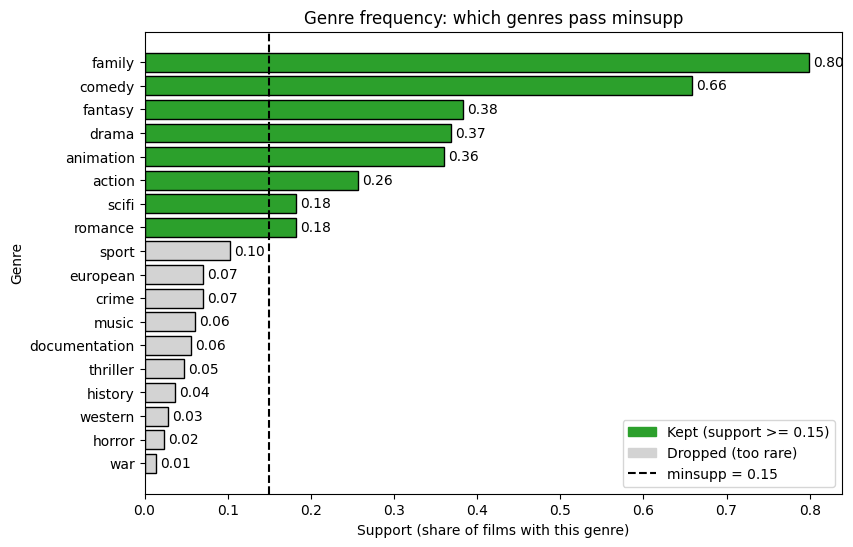

In [ ]:
# =====================  RESULT GRAPH 1: GENRE FREQUENCY  =====================
# [CHANGED] The old 1x3 figure is now three separate figures (one per slide), each with a legend and value labels.

k1 = itemset_table[itemset_table["k"] == 1].sort_values("Support")

plt.figure(figsize=(9, 6))
bars = plt.barh(k1["Itemset"].str.strip("{}"), k1["Support"],
                color=["tab:green" if s == "Keep" else "lightgray" for s in k1["Status"]], edgecolor="black")
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.axvline(minsupp, ls="--", c="black")
plt.legend(handles=[mpatches.Patch(color="tab:green", label=f"Kept (support >= {minsupp})"),
                    mpatches.Patch(color="lightgray", label="Dropped (too rare)"),
                    mlines.Line2D([], [], color="black", ls="--", label=f"minsupp = {minsupp}")], loc="lower right")
plt.title("Genre frequency: which genres pass minsupp")
plt.xlabel("Support (share of films with this genre)")
plt.ylabel("Genre")
plt.grid(False)
plt.show()

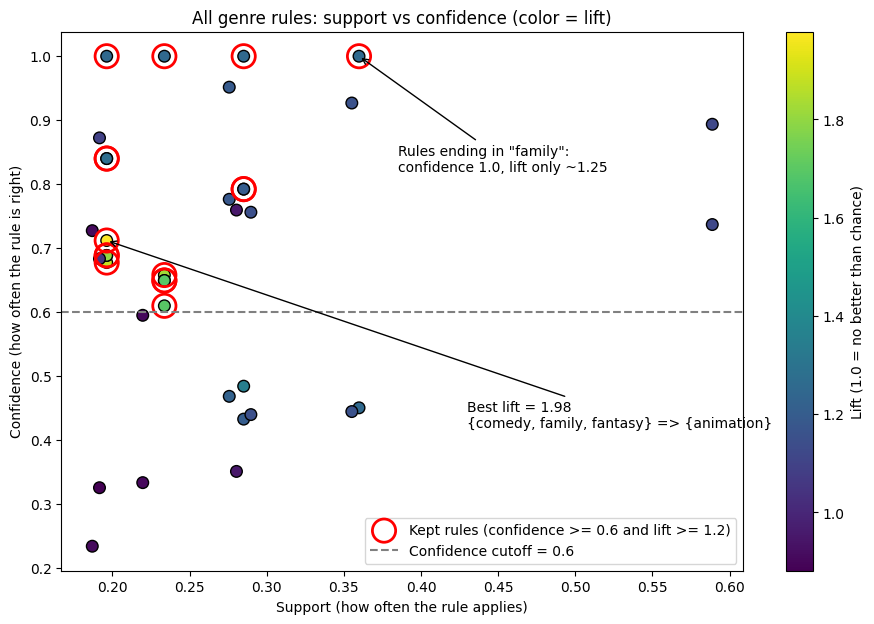

In [ ]:
# =====================  RESULT GRAPH 2: SUPPORT VS CONFIDENCE  =====================
# [CHANGED] Kept rules get a red ring, and the two most important groups of dots are labeled.

kept = all_rules[(all_rules["Confidence"] >= MIN_CONF) & (all_rules["Lift"] >= MIN_LIFT)]
best = all_rules.iloc[0]                                                     # highest lift
fam = all_rules[(all_rules["consequent"] == frozenset(["family"])) & (all_rules["Confidence"] >= 0.999)].sort_values("Support").iloc[-1]

fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(all_rules["Support"], all_rules["Confidence"], c=all_rules["Lift"], cmap="viridis", s=70, edgecolor="k")
ax.scatter(kept["Support"], kept["Confidence"], s=280, facecolors="none", edgecolors="red", linewidths=2,
           label=f"Kept rules (confidence >= {MIN_CONF} and lift >= {MIN_LIFT})")
ax.axhline(MIN_CONF, ls="--", c="gray", label=f"Confidence cutoff = {MIN_CONF}")
ax.annotate(f"Best lift = {best['Lift']:.2f}\n{best['Rule']}", xy=(best["Support"], best["Confidence"]),
            xytext=(0.43, 0.42), ha="left", arrowprops=dict(arrowstyle="->"))
ax.annotate('Rules ending in "family":\nconfidence 1.0, lift only ~1.25', xy=(fam["Support"], fam["Confidence"]),
            xytext=(0.385, 0.82), ha="left", arrowprops=dict(arrowstyle="->"))
fig.colorbar(sc, ax=ax, label="Lift (1.0 = no better than chance)")
ax.set_title("All genre rules: support vs confidence (color = lift)")
ax.set_xlabel("Support (how often the rule applies)")
ax.set_ylabel("Confidence (how often the rule is right)")
ax.legend(loc="lower right")
ax.grid(False)
plt.show()

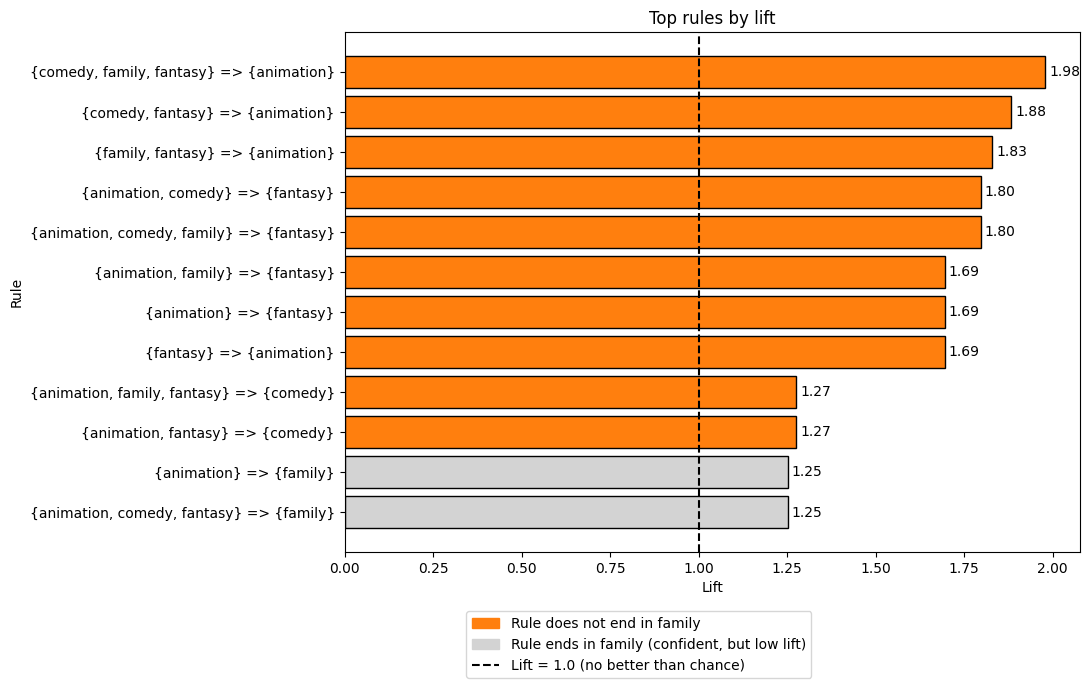

In [ ]:
# =====================  RESULT GRAPH 3: TOP RULES BY LIFT  =====================
# [CHANGED] Rules ending in family are gray, the others orange, with the lift value on every bar.

top = rules_f.head(12).iloc[::-1]
colors = ["lightgray" if f else "tab:orange" for f in top["Ends in family"]]

plt.figure(figsize=(11, 7))
bars = plt.barh(top["Rule"], top["Lift"], color=colors, edgecolor="black")
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.axvline(1.0, ls="--", c="black")
plt.legend(handles=[mpatches.Patch(color="tab:orange", label="Rule does not end in family"),
                    mpatches.Patch(color="lightgray", label='Rule ends in family (confident, but low lift)'),
                    mlines.Line2D([], [], color="black", ls="--", label="Lift = 1.0 (no better than chance)")],
           loc="upper center", bbox_to_anchor=(0.4, -0.1))
plt.title("Top rules by lift")
plt.xlabel("Lift")
plt.ylabel("Rule")
plt.grid(False)
plt.tight_layout()
plt.show()

## Talking points for your presentation

- **Descriptive first:** 579 films, but only films with a genre list can be baskets, so Apriori uses the films with a list (minus 8 wrong versions).
- **Gross is extremely skewed:** use the log scale; the mean is well above the median.
- **Why minsupp = 0.15:** it keeps itemsets that appear in about 30+ films and still reaches 4-genre itemsets (see the sensitivity table).
- **Lead with lift, not confidence:** `family` is in about 80% of films, so rules ending in family look confident but add little (see the "Ends in family" column).
- **Validation:** the given train/test split is used; rules mined on train alone are checked on test (small test set).
- **Limits:** genre tags are noisy and the films with lists are a subset of all Disney films, so the rules describe those films.
- **Hand-off to your groupmate:** the Apriori file is `disney_apriori_clean.csv`; regression can start from the same train/test CSVs, but should decide for itself which of the 579 films to use.